First Five Rows:
   gender   age  hypertension  heart_disease smoking_history    bmi  \
0  Female  80.0             0              1           never  25.19   
1  Female  54.0             0              0         No Info  27.32   
2    Male  28.0             0              0           never  27.32   
3  Female  36.0             0              0         current  23.45   
4    Male  76.0             1              1         current  20.14   

   HbA1c_level  blood_glucose_level  diabetes  
0          6.6                  140         0  
1          6.6                   80         0  
2          5.7                  158         0  
3          5.0                  155         0  
4          4.8                  155         0  

Dataset Shape:
(100000, 9)

Missing Values:
gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               

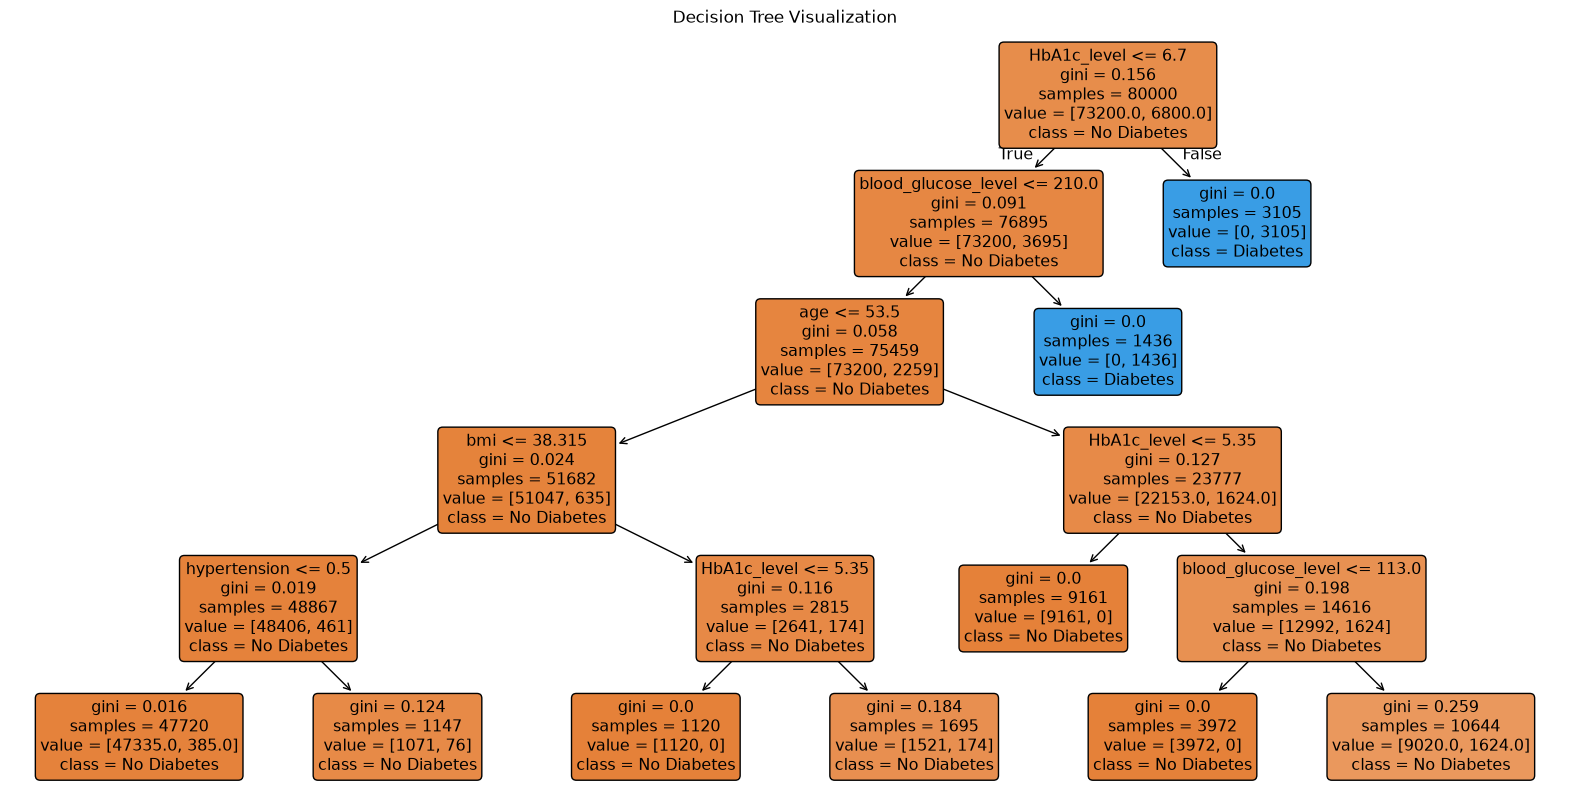


Confusion Matrix:
[[18300     0]
 [  554  1146]]


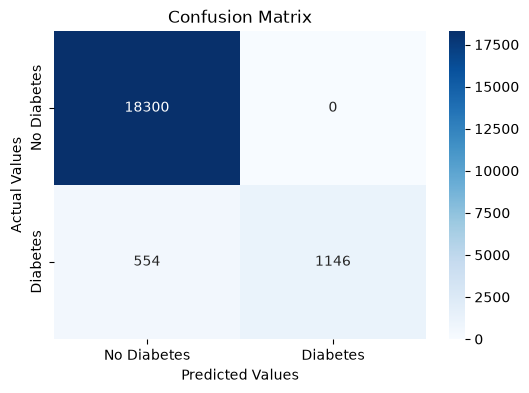


MODEL EVALUATION
Accuracy: 0.9723
Precision: 1.0
Recall: 0.6741176470588235
F1-Score: 0.8053408292340126

Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.99     18300
           1       1.00      0.67      0.81      1700

    accuracy                           0.97     20000
   macro avg       0.99      0.84      0.90     20000
weighted avg       0.97      0.97      0.97     20000


Feature Importance:
HbA1c_level            0.656437
blood_glucose_level    0.328884
age                    0.012060
bmi                    0.001724
hypertension           0.000895
gender                 0.000000
heart_disease          0.000000
smoking_history        0.000000
dtype: float64


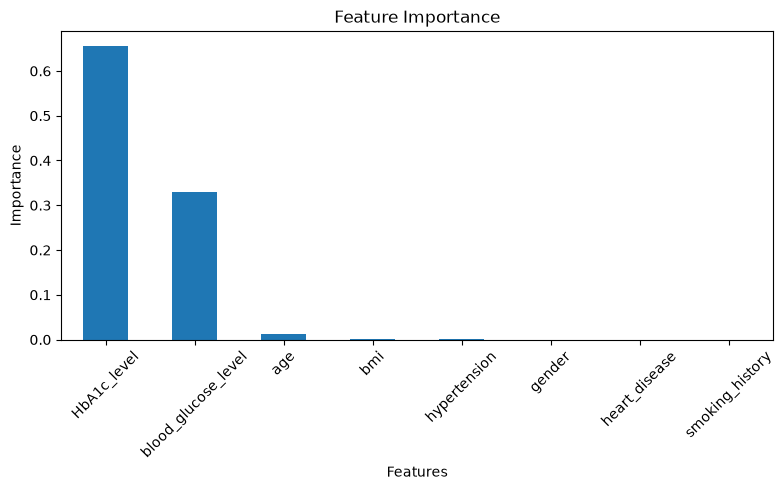

In [1]:

# DECISION TREE CLASSIFICATION
# Model Building, Visualization and Evaluation

# 1. Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import classification_report

# 2. Load Dataset
df = pd.read_csv("diabetes_prediction_dataset.csv")

print("First Five Rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

# 3. Check Missing Values
print("\nMissing Values:")
print(df.isnull().sum())

# 4. Convert Categorical Data into Numerical Data
le = LabelEncoder()

df['gender'] = le.fit_transform(df['gender'])
df['smoking_history'] = le.fit_transform(df['smoking_history'])

# 5. Separate Input and Output
X = df.drop('diabetes', axis=1)
y = df['diabetes']

# 6. Split Dataset into Training and Testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("\nTraining Data:", X_train.shape)
print("Testing Data:", X_test.shape)

# 7. Build Decision Tree Model
model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=5,
    random_state=42
)

# 8. Train the Model
model.fit(X_train, y_train)

print("\nDecision Tree Model Built Successfully!")

# 9. Predict the Output
y_pred = model.predict(X_test)

print("\nActual Values:")
print(y_test.values[:20])

print("\nPredicted Values:")
print(y_pred[:20])

# 10. Visualize Decision Tree
plt.figure(figsize=(20, 10))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=['No Diabetes', 'Diabetes'],
    filled=True,
    rounded=True
)

plt.title("Decision Tree Visualization")
plt.show()

# 11. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Diabetes', 'Diabetes'],
    yticklabels=['No Diabetes', 'Diabetes']
)

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("Confusion Matrix")
plt.show()

# 12. Evaluate Model Performance
print("\nMODEL EVALUATION")

print("Accuracy:", accuracy_score(y_test, y_pred))

print("Precision:", precision_score(y_test, y_pred))

print("Recall:", recall_score(y_test, y_pred))

print("F1-Score:", f1_score(y_test, y_pred))

# 13. Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# 14. Feature Importance Visualization
importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("\nFeature Importance:")
print(importance)

plt.figure(figsize=(8, 5))

importance.plot(kind='bar')

plt.title("Feature Importance")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
